<a href="https://colab.research.google.com/github/Gayathridevi-gj/Job-Acceptance-Prediction-System/blob/main/PROJECT3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
##Packages

In [1]:
import pandas as pd
import plotly.express as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import zscore

File Reading and Understanding

In [3]:
df = pd.read_csv("/content/HR_Job_Placement_Dataset.csv")

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51500 entries, 0 to 51499
Data columns (total 26 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   age_years                  51500 non-null  int64  
 1   gender                     51500 non-null  object 
 2   ssc_percentage             48919 non-null  float64
 3   hsc_percentage             49435 non-null  float64
 4   degree_percentage          51500 non-null  float64
 5   degree_specialization      51500 non-null  object 
 6   technical_score            51500 non-null  float64
 7   aptitude_score             51500 non-null  float64
 8   communication_score        51500 non-null  float64
 9   skills_match_percentage    51500 non-null  float64
 10  certifications_count       51500 non-null  int64  
 11  internship_experience      51500 non-null  object 
 12  years_of_experience        51500 non-null  int64  
 13  career_switch_willingness  43034 non-null  obj

In [5]:
df.isna().sum()

,0
age_years,0
gender,0
ssc_percentage,2581
hsc_percentage,2065
degree_percentage,0
degree_specialization,0
technical_score,0
aptitude_score,0
communication_score,0
skills_match_percentage,0


In [6]:
pd.set_option('display.max_columns', None)

In [7]:
df.head(10)

,age_years,gender,ssc_percentage,hsc_percentage,degree_percentage,degree_specialization,technical_score,aptitude_score,communication_score,skills_match_percentage,certifications_count,internship_experience,years_of_experience,career_switch_willingness,relevant_experience,previous_ctc_lpa,expected_ctc_lpa,company_tier,job_role_match,competition_level,bond_requirement,notice_period_days,layoff_history,employment_gap_months,relocation_willingness,status
0,27,Male,65.061656,83.842578,75.856526,Computer Science,58.221909,89.566305,64.474484,79.548913,2,No,1,Willing,Relevant,3.530557,5.805850,Tier 3,Not Matched,Medium,Not Required,15.0,No,18.0,Not Willing,Not Placed
1,24,Male,67.885626,64.973305,73.093588,Electronics,71.927978,54.591971,61.077306,73.316134,1,yes,0,Not Willing,Relevant,9.858155,10.807739,Tier 1,Matched,High,Required,0.0,NaN,NaN,Not Willing,Not Placed
2,33,Female,73.892471,68.834121,90.196460,Information Technology,72.445041,58.587088,79.494739,75.466980,1,Yes,1,Willing,Relevant,5.801817,5.476839,Tier 3,Not Matched,Low,Not Required,0.0,No,3.0,Not Willing,Placed
3,31,Male,74.145568,76.255126,75.586731,Mechanical,78.855676,61.022065,53.740386,73.676449,2,No,0,Not Willing,Relevant,2.129805,9.980580,Tier 2,Matched,Low,Not Required,0.0,Yes,6.0,NaN,Not Placed
4,28,Male,60.475937,65.786336,80.801010,Information Technology,68.286776,65.713731,61.438314,88.994847,1,No,0,Willing,Not Relevant,7.948314,8.921233,Tier 2,Matched,Medium,Not Required,0.0,No,3.0,Willing,Not Placed
5,33,Female,60.641768,66.151843,78.203455,Others,85.063940,46.293090,47.638858,78.307411,1,Yes,1,NaN,Relevant,4.918530,3.000000,Tier 2,Not Matched,Low,Not Required,60.0,No,0.0,Not Willing,Placed
6,25,Female,78.224191,69.578282,79.870959,Mechanical,85.168067,47.188328,70.348778,79.935956,1,Yes,1,Not Willing,NaN,7.946910,7.114406,Tier 2,Matched,Low,Not Required,0.0,No,0.0,Not Willing,Placed
7,27,Female,NaN,69.111350,75.430679,Others,75.672196,56.391743,76.383155,77.546335,0,Yes,3,Willing,Relevant,8.056013,3.103734,Tier 1,Matched,Medium,Not Required,0.0,No,0.0,Not Willing,Placed
8,30,Female,69.535754,78.757507,79.757543,Mechanical,78.282823,62.647484,81.629846,67.931840,3,yes,2,Not Willing,Relevant,4.190206,3.000000,Tier 3,Matched,Low,Not Required,NaN,No,0.0,NaN,Placed
9,23,female,70.972461,78.101606,72.767897,Mechanical,54.554258,61.055905,59.567957,95.125145,0,No,2,Willing,Relevant,5.925225,3.091102,Tier 1,Not Matched,High,Required,0.0,No,0.0,Willing,Not Placed


Handling Missing Values

In [9]:
ssc_median = df['ssc_percentage'].median()
hsc_median = df['hsc_percentage'].median()
df['ssc_percentage'] = df['ssc_percentage'].fillna(ssc_median)
df['hsc_percentage'] = df['hsc_percentage'].fillna(hsc_median)

In [10]:
most_frequent_willingness = df['career_switch_willingness'].mode()[0]
df['career_switch_willingness'] = df['career_switch_willingness'].fillna(most_frequent_willingness)

EDA using Ydata Profiling to Understand each column

In [ ]:
!pip install ydata_profiling
!pip install fg-data-profiling

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.8/400.8 kB 14.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 20.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 70.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 682.5/682.5 kB 37.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.4/105.4 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.5/400.5 kB 8.7 MB/s eta 0:00:00


In [ ]:
import data_profiling
from data_profiling import ProfileReport

In [ ]:
EDA = ProfileReport(df,title='EDA')
EDA

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 26/26 [00:02<00:00, 10.63it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [11]:
(df['relevant_experience']== 'Not Relevant').sum()

np.int64(16769)

In [12]:
df[df['relevant_experience']== 'Not Relevant']

,age_years,gender,ssc_percentage,hsc_percentage,degree_percentage,degree_specialization,technical_score,aptitude_score,communication_score,skills_match_percentage,certifications_count,internship_experience,years_of_experience,career_switch_willingness,relevant_experience,previous_ctc_lpa,expected_ctc_lpa,company_tier,job_role_match,competition_level,bond_requirement,notice_period_days,layoff_history,employment_gap_months,relocation_willingness,status
4,28,Male,60.475937,65.786336,80.801010,Information Technology,68.286776,65.713731,61.438314,88.994847,1,No,0,Willing,Not Relevant,7.948314,8.921233,Tier 2,Matched,Medium,Not Required,0.0,No,3.0,Willing,Not Placed
12,31,Female,72.733744,74.350728,76.396765,Others,85.602155,58.459018,77.107255,74.435967,1,No,0,Willing,Not Relevant,6.618069,3.708885,Tier 3,Matched,Low,Required,90.0,No,3.0,Willing,Not Placed
20,25,Female,70.133988,56.638218,73.657848,Information Technology,66.928780,67.491887,75.275745,74.362047,0,Yes,3,Not Willing,Not Relevant,2.246799,10.800252,Tier 3,NaN,Medium,Not Required,60.0,No,0.0,Willing,Not Placed
22,28,Male,69.189160,67.313938,81.496831,Others,64.438359,60.303041,78.165128,91.512091,1,Yes,4,Not Willing,Not Relevant,3.426834,3.767979,Tier 3,Matched,Low,Not Required,15.0,No,0.0,Willing,Placed
24,34,Male,80.267286,72.846671,79.989130,Computer Science,65.954073,67.598910,69.353341,79.067344,0,No,4,Not Willing,Not Relevant,7.359749,3.000000,Tier 3,Matched,Medium,Not Required,0.0,No,12.0,Not Willing,Placed
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51481,26,Female,65.312662,70.407253,82.626886,Computer Science,71.054893,72.931057,76.778258,75.129767,2,Yes,2,Not Willing,Not Relevant,3.786330,4.592644,Tier 3,Not Matched,Low,Required,0.0,No,0.0,Willing,Placed
51491,26,Female,68.845365,75.808474,64.878803,Computer Science,74.765058,58.997111,55.769771,61.490815,3,Yes,1,Not Willing,Not Relevant,6.100976,9.099572,Tier 1,Matched,Medium,Required,0.0,No,12.0,Not Willing,Not Placed
51495,24,Female,65.747180,72.063946,72.247881,Electronics,55.923057,73.208032,69.108895,63.992488,2,No,0,Not Willing,Not Relevant,1.874355,6.315211,Tier 1,Matched,Low,Required,0.0,No,3.0,NaN,Not Placed
51496,22,Male,61.921459,66.729203,55.000000,Others,69.525121,70.245612,54.959868,88.514232,0,Yes,1,Not Willing,Not Relevant,7.848456,8.655391,Tier 1,Matched,Medium,Not Required,60.0,No,0.0,Not Willing,Placed


In [13]:
((df['years_of_experience'] == 0) & (df['internship_experience'] == 0) & (df['relevant_experience']== 'Not Relevant')).sum()

np.int64(0)

In [14]:
df['relevant_experience'] = df['relevant_experience'].fillna('Unknown')

Using plot to view its spread and check for logics to handle missing values


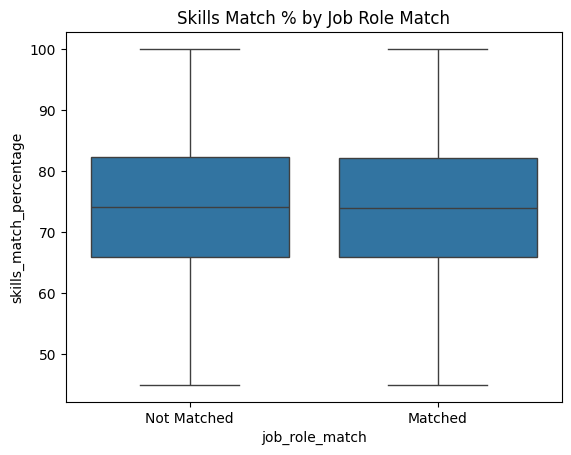

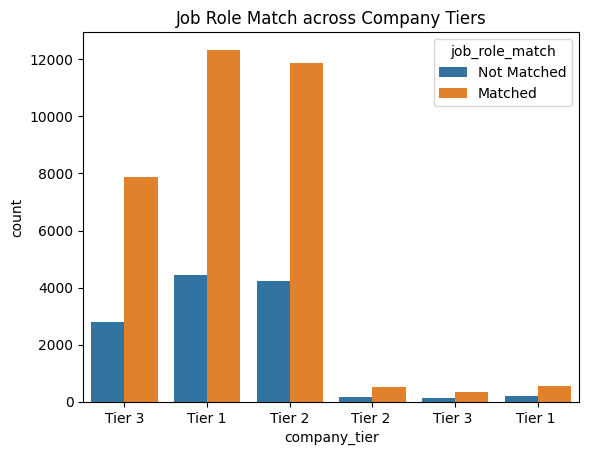

In [15]:
# Visual 1: Do higher skills match percentages lead to a Job Role Match?
sns.boxplot(x="job_role_match", y="skills_match_percentage", data=df)
plt.title("Skills Match % by Job Role Match")
plt.show()

# Visual 2: Does the company tier affect Job Role Match?
sns.countplot(x="company_tier", hue="job_role_match", data=df)
plt.title("Job Role Match across Company Tiers")
plt.show()

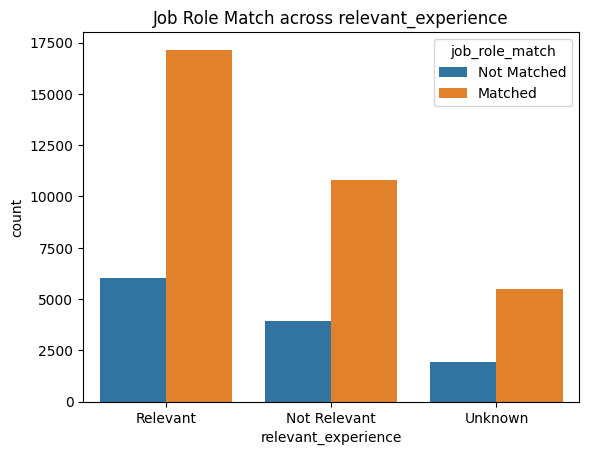

In [16]:
sns.countplot(x="relevant_experience", hue="job_role_match", data=df)
plt.title("Job Role Match across relevant_experience")
plt.show()

In [17]:
df.loc[
    (df["relevant_experience"]=='Not Relevant') | (df["company_tier"] == 'Tier 3'),
    "job_role_match",
] = "Not Matched"

In [18]:
job_role_match=df["job_role_match"].mode()
df["job_role_match"] = df["job_role_match"].fillna(job_role_match[0])

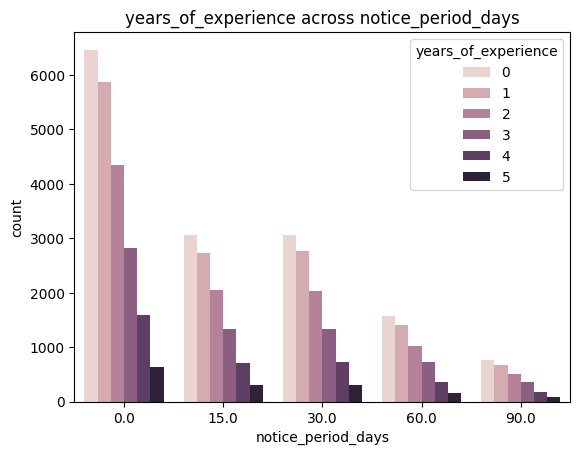

In [19]:
sns.countplot(x="notice_period_days", hue="years_of_experience", data=df)
plt.title("years_of_experience across notice_period_days")
plt.show()

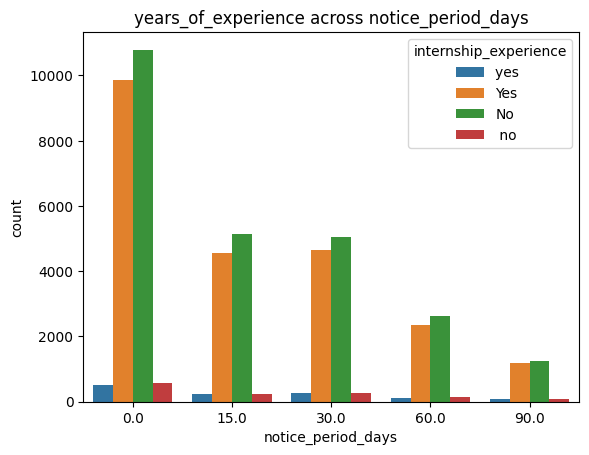

In [20]:
sns.countplot(x="notice_period_days", hue="internship_experience", data=df)
plt.title("years_of_experience across notice_period_days")
plt.show()

In [22]:
df.loc[
    (df['notice_period_days'].isnull()) & (df['years_of_experience'] == 0),
    'notice_period_days',
] =0.0

In [23]:
df[df['relocation_willingness'].isnull()]

,age_years,gender,ssc_percentage,hsc_percentage,degree_percentage,degree_specialization,technical_score,aptitude_score,communication_score,skills_match_percentage,certifications_count,internship_experience,years_of_experience,career_switch_willingness,relevant_experience,previous_ctc_lpa,expected_ctc_lpa,company_tier,job_role_match,competition_level,bond_requirement,notice_period_days,layoff_history,employment_gap_months,relocation_willingness,status
3,31,Male,74.145568,76.255126,75.586731,Mechanical,78.855676,61.022065,53.740386,73.676449,2,No,0,Not Willing,Relevant,2.129805,9.980580,Tier 2,Matched,Low,Not Required,0.0,Yes,6.0,NaN,Not Placed
8,30,Female,69.535754,78.757507,79.757543,Mechanical,78.282823,62.647484,81.629846,67.931840,3,yes,2,Not Willing,Relevant,4.190206,3.000000,Tier 3,Not Matched,Low,Not Required,NaN,No,0.0,NaN,Placed
13,28,Male,64.600706,72.014383,76.595184,Computer Science,63.320951,69.529122,69.894391,74.861257,0,Yes,4,Willing,Unknown,7.285383,12.339071,Tier 2,Matched,High,Not Required,30.0,No,0.0,NaN,Placed
14,25,Male,88.516513,71.517299,74.026919,Electronics,60.060036,63.699078,60.432547,66.558216,2,Yes,3,Not Willing,Unknown,5.629606,6.341400,Tier 3,Not Matched,Medium,Required,30.0,No,0.0,NaN,Not Placed
15,24,Male,75.606267,63.100681,66.104410,Computer Science,56.249893,57.687563,74.740999,98.117012,2,No,3,Willing,Relevant,5.249854,9.205484,Tier 3,Not Matched,Low,Not Required,0.0,No,6.0,NaN,Not Placed
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51466,22,Male,74.640718,72.583698,76.386622,Electronics,63.338786,69.990309,65.510441,88.980929,2,No,0,Willing,Relevant,6.184223,7.386148,Tier 2,Matched,Low,Not Required,15.0,NaN,0.0,NaN,Placed
51480,26,Female,59.085833,68.795821,82.025453,Mechanical,67.147475,67.903147,72.304220,70.019765,0,Yes,2,Not Willing,Relevant,3.756132,13.043249,Tier 1,Matched,Low,Required,90.0,No,0.0,NaN,Not Placed
51492,23,Female,64.420976,80.759113,69.340480,Mechanical,46.707498,66.843322,68.341317,77.311556,2,no,0,Not Willing,Relevant,4.259285,13.007079,Tier 1,Matched,Low,Not Required,0.0,No,0.0,NaN,Not Placed
51495,24,Female,65.747180,72.063946,72.247881,Electronics,55.923057,73.208032,69.108895,63.992488,2,No,0,Not Willing,Not Relevant,1.874355,6.315211,Tier 1,Not Matched,Low,Required,0.0,No,3.0,NaN,Not Placed


In [24]:
df["notice_period_days"] = df.groupby("company_tier")[
    "notice_period_days"
].transform(lambda x: x.fillna(x.median()))

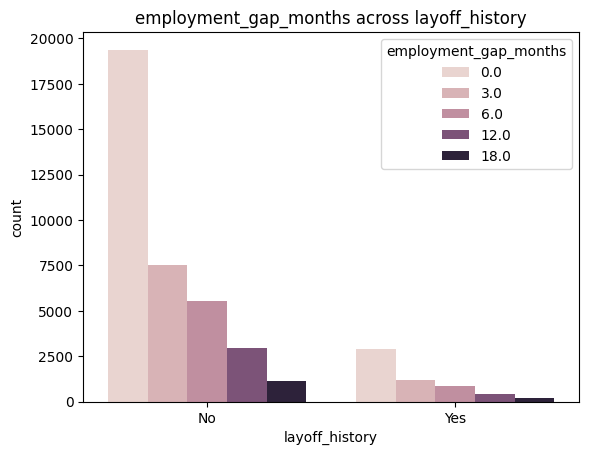

In [ ]:
sns.countplot(x="layoff_history", hue="employment_gap_months", data=df)
plt.title("employment_gap_months across layoff_history")
plt.show()

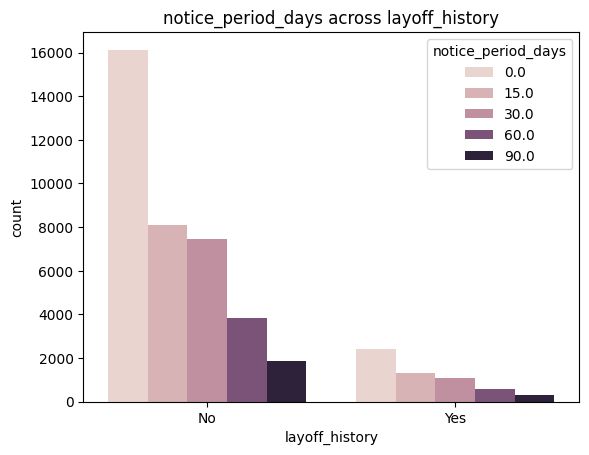

In [ ]:
sns.countplot(x="layoff_history", hue="notice_period_days", data=df)
plt.title("notice_period_days across layoff_history")
plt.show()

In [25]:
df.loc[
    (df['layoff_history'].isnull()) & (df['employment_gap_months'] == 0),
    'layoff_history',
] = 'No'

In [26]:
df.loc[
    (df['layoff_history'].isnull()) & (df['notice_period_days'] == 0.0),
    'layoff_history',
] = 'No'

In [27]:
layoff=df["layoff_history"].mode()
df["layoff_history"] = df["layoff_history"].fillna(layoff[0])

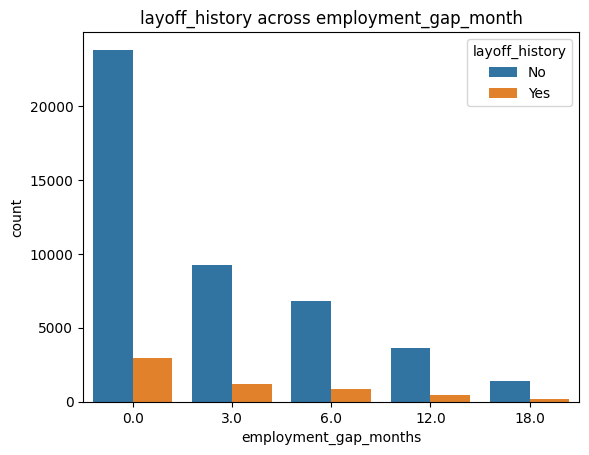

In [ ]:
sns.countplot(x="employment_gap_months", hue="layoff_history", data=df)
plt.title("layoff_history across employment_gap_month")
plt.show()

In [28]:
gap=df["employment_gap_months"].mode()
df["employment_gap_months"] = df["employment_gap_months"].fillna(gap[0])

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


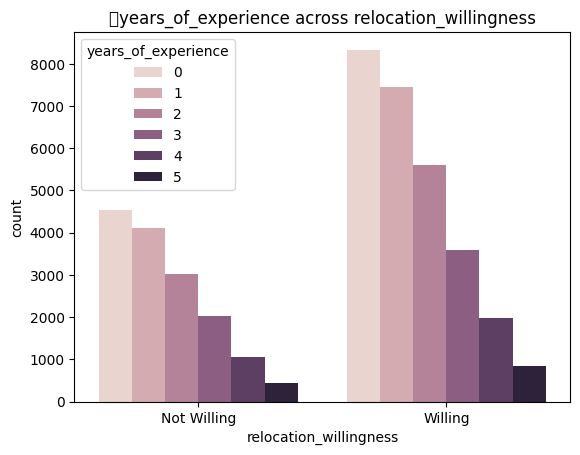

In [29]:
sns.countplot(x="relocation_willingness", hue="years_of_experience", data=df)
plt.title("	years_of_experience across relocation_willingness")
plt.show()

In [30]:
relocation=df["relocation_willingness"].mode()
df["relocation_willingness"] = df["relocation_willingness"].fillna(relocation[0])

Handling Duplicate Rows

In [31]:
duplicate_count = df.duplicated().sum()
print(f"Total exact duplicate rows: {duplicate_count}")

Total exact duplicate rows: 1376


In [32]:
df.sort_values(by="technical_score", ascending=False, inplace=True)
df.drop_duplicates(
    subset=["age_years", "gender", "ssc_percentage"], keep="first", inplace=True
)

Handling Categorical Inconsistency

In [33]:
categorical_cols = df.select_dtypes(include=["object"]).columns

for col in categorical_cols:
    # Convert all text to lowercase (or .str.title() for Title Case)
    df[col] = df[col].astype(str).str.lower()

    # Remove accidental leading and trailing spaces
    df[col] = df[col].str.strip()

In [ ]:
df.head(5)

,age_years,gender,ssc_percentage,hsc_percentage,degree_percentage,degree_specialization,technical_score,aptitude_score,communication_score,skills_match_percentage,certifications_count,internship_experience,years_of_experience,career_switch_willingness,relevant_experience,previous_ctc_lpa,expected_ctc_lpa,company_tier,job_role_match,competition_level,bond_requirement,notice_period_days,layoff_history,employment_gap_months,relocation_willingness,status
35904,33,female,79.308804,79.147926,64.443048,information technology,100.0,66.433973,69.812933,77.163241,1,yes,1,willing,relevant,6.420778,7.018160,tier 1,matched,medium,not required,0.0,no,18.0,willing,placed
9648,25,female,76.879422,53.826725,81.011499,computer science,100.0,60.028986,61.811352,79.261906,3,no,0,willing,relevant,4.798244,8.483084,tier 3,not matched,low,not required,15.0,no,3.0,willing,placed
14066,33,male,70.705391,68.987199,58.173371,computer science,100.0,70.957044,69.543899,73.099858,3,yes,2,not willing,not relevant,1.000000,10.002975,tier 3,not matched,low,not required,90.0,no,0.0,not willing,placed
11912,25,female,69.372785,65.783793,67.806543,electronics,100.0,53.844054,65.439851,100.000000,1,no,3,not willing,relevant,2.518770,8.953512,tier 3,not matched,medium,not required,0.0,no,6.0,willing,placed
19819,32,male,62.885841,79.867802,61.003825,information technology,100.0,53.114164,65.249030,100.000000,1,no,0,not willing,not relevant,5.924396,7.810768,tier 1,not matched,low,required,0.0,yes,18.0,not willing,not placed


Store a copy before encoding

In [34]:
df_clean = df.copy()

Encoding

In [35]:
le_job = LabelEncoder()
df['company_tier'] = le_job.fit_transform(df['company_tier'])

In [36]:
df['competition_level'] = le_job.fit_transform(df['competition_level'])

In [37]:
df['job_role_match'] = le_job.fit_transform(df['job_role_match'])
df['status'] = le_job.fit_transform(df['status'])

In [38]:
one_hot_cols = [ "gender","degree_specialization","internship_experience","career_switch_willingness","relevant_experience","bond_requirement","layoff_history","relocation_willingness",]

df_final = pd.get_dummies(df, columns=one_hot_cols, drop_first=True, dtype=int)



In [39]:
df_final.head(5)

,age_years,ssc_percentage,hsc_percentage,degree_percentage,technical_score,aptitude_score,communication_score,skills_match_percentage,certifications_count,years_of_experience,previous_ctc_lpa,expected_ctc_lpa,company_tier,job_role_match,competition_level,notice_period_days,employment_gap_months,status,gender_male,degree_specialization_electronics,degree_specialization_information technology,degree_specialization_mechanical,degree_specialization_others,internship_experience_yes,career_switch_willingness_willing,relevant_experience_relevant,relevant_experience_unknown,bond_requirement_required,layoff_history_yes,relocation_willingness_willing
35904,33,79.308804,79.147926,64.443048,100.0,66.433973,69.812933,77.163241,1,1,6.420778,7.018160,0,0,2,0.0,18.0,1,0,0,1,0,0,1,1,1,0,0,0,1
9648,25,76.879422,53.826725,81.011499,100.0,60.028986,61.811352,79.261906,3,0,4.798244,8.483084,2,1,1,15.0,3.0,1,0,0,0,0,0,0,1,1,0,0,0,1
14066,33,70.705391,68.987199,58.173371,100.0,70.957044,69.543899,73.099858,3,2,1.000000,10.002975,2,1,1,90.0,0.0,1,1,0,0,0,0,1,0,0,0,0,0,0
11912,25,69.372785,65.783793,67.806543,100.0,53.844054,65.439851,100.000000,1,3,2.518770,8.953512,2,1,2,0.0,6.0,1,0,1,0,0,0,0,0,1,0,0,0,1
19819,32,62.885841,79.867802,61.003825,100.0,53.114164,65.249030,100.000000,1,0,5.924396,7.810768,0,1,1,0.0,18.0,0,1,0,1,0,0,0,0,0,0,1,1,0


Scaling

In [40]:
columns_to_scale = [
    "ssc_percentage",
    "hsc_percentage",
    "degree_percentage",
    "technical_score",
    "aptitude_score",
    "communication_score",
    "skills_match_percentage",
    "previous_ctc_lpa",
    "expected_ctc_lpa",
    "notice_period_days",
    "employment_gap_months",
]
scaler = StandardScaler()
df[columns_to_scale] = scaler.fit_transform(df[columns_to_scale])


In [41]:
df.loc[
    (df["years_of_experience"] == 0) & (df["internship_experience"] == "No"),
    "relevant_experience",
] = "Not Relevant"
df.loc[
    (df["years_of_experience"] == 0) & (df["status"] == "Not Placed"),
    "previous_ctc_lpa",
] = 0.0
df.loc[df["status"] == "Not Placed", "notice_period_days"] = 0

Status Distribution Across Average Interview Score

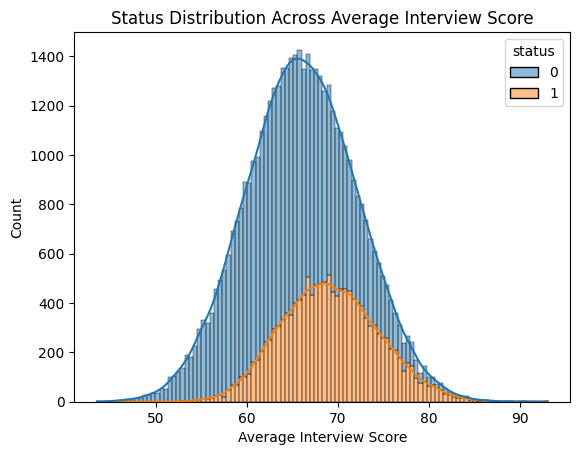

In [43]:
interview_scores = df_clean[['aptitude_score', 'technical_score', 'communication_score']].mean(axis=1)

# Plot the distribution using the standalone Series directly
sns.histplot(x=interview_scores, hue=df["status"], kde=True, multiple="stack")
plt.xlabel("Average Interview Score")
plt.title("Status Distribution Across Average Interview Score")
plt.show()
#1-placed, 0- not placed

status across skills_match_percentage

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


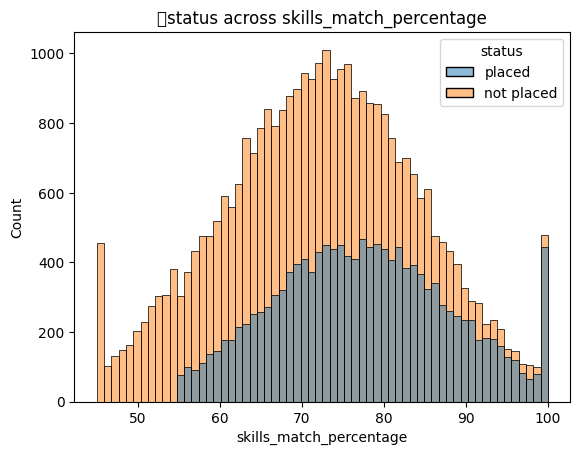

In [44]:
sns.histplot(x="skills_match_percentage", hue="status", data=df_clean)
plt.title("	status across skills_match_percentage")
plt.show()

company tier impact on job acceptance

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


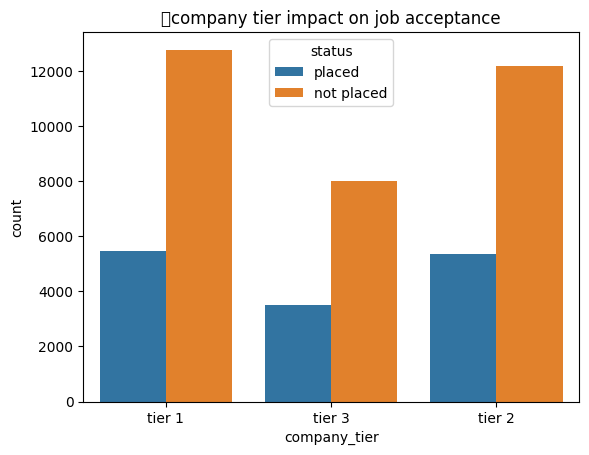

In [45]:
sns.countplot(x="company_tier", hue="status", data=df_clean)
plt.title("	company tier impact on job acceptance")
plt.show()

competition_level impact on job acceptance

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


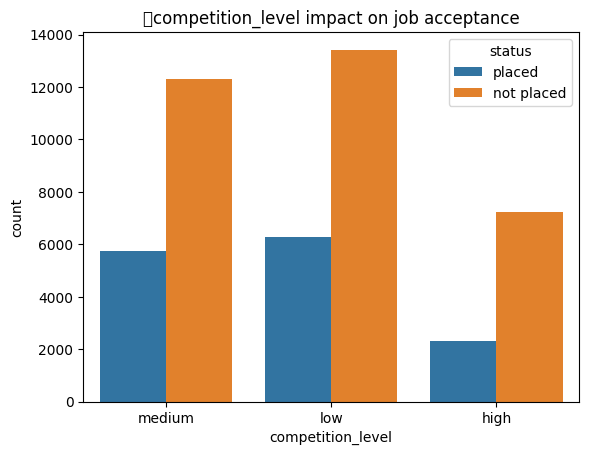

In [46]:
sns.countplot(x="competition_level", hue="status", data=df_clean)
plt.title("	competition_level impact on job acceptance")
plt.show()

 Feature Engineering

Experience category (Fresher / Junior / Senior)

In [47]:
def categorize_experience(years):
    if years == 0:
        return "Fresher"
    elif 1 <= years < 5:
        return "Junior"
    else:
        return "Senior"


df["experience_category"] = df["years_of_experience"].apply(
    categorize_experience
)


Academic performance bands

In [48]:
df["academic_avg"] = df[
    ["ssc_percentage", "hsc_percentage", "degree_percentage"]
].mean(axis=1)


# 2. Assign to performance bands
def get_academic_band(score):
    if score >= 80:
        return "Excellent"
    elif 65 <= score < 80:
        return "Good"
    else:
        return "Average"


df["academic_performance_band"] = df["academic_avg"].apply(get_academic_band)

Skills match level (Low / Medium / High)

In [49]:
def get_skills_level(pct):
    if pct < 60:
        return "Low"
    elif 60 <= pct <= 80:
        return "Medium"
    else:
        return "High"


df["skills_match_level"] = df["skills_match_percentage"].apply(
    get_skills_level
)

Interview performance category

In [50]:
df["interview_avg"] = df[
    ["technical_score", "aptitude_score", "communication_score"]
].mean(axis=1)

# Divide into tertiles or set strict thresholds (e.g., >75 is High)
df["interview_performance_category"] = pd.qcut(
    df["interview_avg"], q=3, labels=["Low", "Medium", "High"])

Placement probability score

In [52]:
df["academic_avg"] = df[
    ["ssc_percentage", "hsc_percentage", "degree_percentage"]
].mean(axis=1)
df["interview_avg"] = df[
    ["technical_score", "aptitude_score", "communication_score"]
].mean(axis=1)
df["placement_points"] = 0
df.loc[df["academic_avg"] >= 75, "placement_points"] += 30
df.loc[df["interview_avg"] >= 70, "placement_points"] += 40
df.loc[df["skills_match_percentage"] >= 80, "placement_points"] += 30
df["placement_probability_score"] = df["placement_points"] / 100
print(df[["academic_avg", "interview_avg", "placement_probability_score"]])

       academic_avg  interview_avg  placement_probability_score
35904      0.236412       1.103865                          0.0
9648      -0.157459       0.618509                          0.0
14066     -0.865012       1.246979                          0.0
11912     -0.596978       0.532773                          0.0
19819     -0.595058       0.501780                          0.0
...             ...            ...                          ...
18588     -0.872568      -0.605747                          0.0
14079     -0.534340      -1.220972                          0.0
20682      0.282207      -0.877300                          0.0
11965     -0.239403      -0.477292                          0.0
16006      0.193121      -1.160783                          0.0

[47289 rows x 3 columns]


 Machine Learning Modeling

In [53]:
# 1. Define your features (X) and target variable (y) using the encoded df_final
X = df_final.drop(columns=['status'])
y = df_final['status']

# 2. Split the dataset into training (80%) and testing sets (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training set size: {X_train.shape}")
print(f"Testing set size: {X_test.shape}")

Training set size: (37831, 29)
Testing set size: (9458, 29)


In [54]:
# 3. Train a Decision Tree Classifier as an example
clf = DecisionTreeClassifier(random_state=42, max_depth=5)
clf.fit(X_train, y_train)

# 4. Predict and evaluate
y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.83      0.91      0.87      6592
           1       0.73      0.58      0.65      2866

    accuracy                           0.81      9458
   macro avg       0.78      0.75      0.76      9458
weighted avg       0.80      0.81      0.80      9458



Candidate Performance Analysis

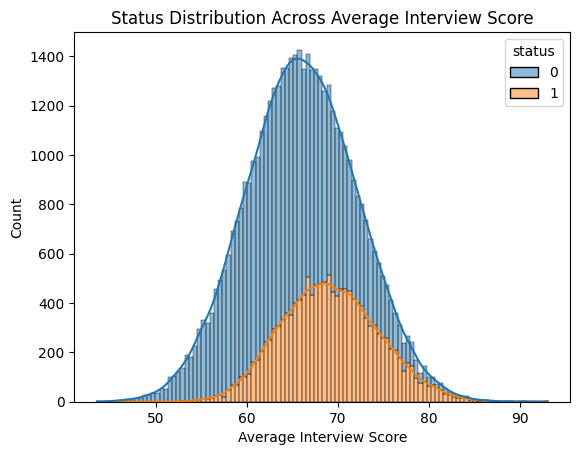

In [55]:
interview_scores = df_clean[['aptitude_score', 'technical_score', 'communication_score']].mean(axis=1)

# Plot the distribution using the standalone Series directly
sns.histplot(x=interview_scores, hue=df["status"], kde=True, multiple="stack")
plt.xlabel("Average Interview Score")
plt.title("Status Distribution Across Average Interview Score")
plt.show()


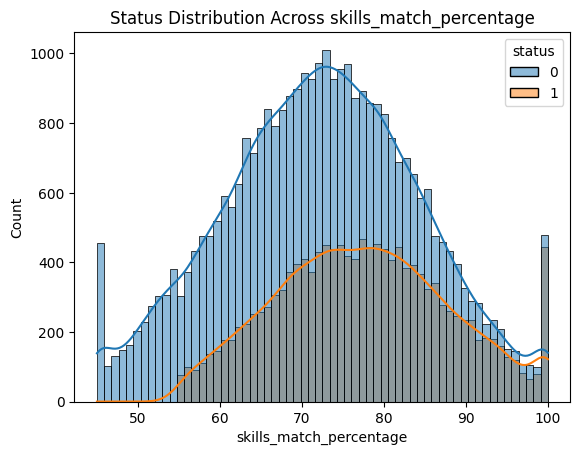

In [56]:
sns.histplot(x="skills_match_percentage", hue=df["status"], kde=True, data=df_clean)
plt.xlabel("skills_match_percentage")
plt.title("Status Distribution Across skills_match_percentage")
plt.show()

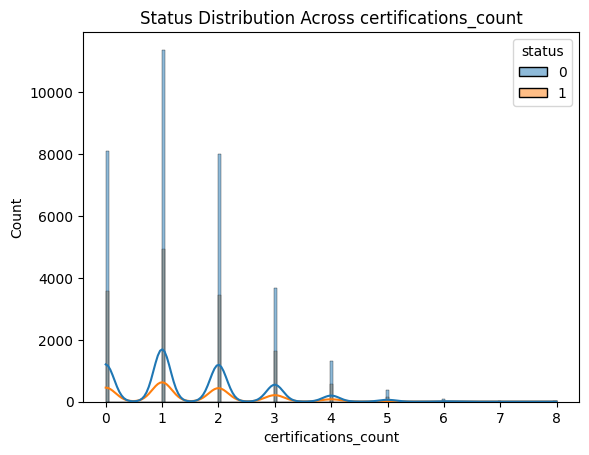

In [57]:
sns.histplot(x="certifications_count", hue=df["status"], kde=True, data=df_clean)
plt.xlabel("certifications_count")
plt.title("Status Distribution Across certifications_count")
plt.show()

In [ ]:
df.head(5)

,age_years,gender,ssc_percentage,hsc_percentage,degree_percentage,degree_specialization,technical_score,aptitude_score,communication_score,skills_match_percentage,certifications_count,internship_experience,years_of_experience,career_switch_willingness,relevant_experience,previous_ctc_lpa,expected_ctc_lpa,company_tier,job_role_match,competition_level,bond_requirement,notice_period_days,layoff_history,employment_gap_months,relocation_willingness,status,experience_category,academic_avg,academic_performance_band,skills_match_level,interview_avg,interview_performance_category,placement_points,placement_probability_score,overall_academics
35904,33,female,1.171447,0.912870,-1.375082,information technology,2.689371,0.245618,0.376605,0.272557,1,yes,1,willing,relevant,0.741961,-0.313109,0,0,2,not required,-0.807515,no,3.405398,willing,1,Junior,0.236412,Average,Low,1.103865,High,0,0.0,0.236412
9648,25,female,0.861951,-2.342605,1.008277,computer science,2.689371,-0.400907,-0.432936,0.450249,3,no,0,willing,relevant,-0.021823,0.154346,2,1,1,not required,-0.196050,no,0.002217,willing,1,Fresher,-0.157459,Average,Low,0.618509,High,0,0.0,-0.157459
14066,33,male,0.075400,-0.393466,-2.276970,computer science,2.689371,0.702180,0.349386,-0.071484,3,yes,2,not willing,not relevant,-1.809791,0.639342,2,1,1,not required,2.861273,no,-0.678420,not willing,1,Junior,-0.865012,Average,Low,1.246979,High,0,0.0,-0.865012
11912,25,female,-0.094370,-0.805318,-0.891246,electronics,2.689371,-1.025219,-0.065831,2.206118,1,no,3,not willing,relevant,-1.094852,0.304460,2,1,2,not required,-0.807515,no,0.682853,willing,1,Junior,-0.596978,Average,Low,0.532773,High,0,0.0,-0.596978
19819,32,male,-0.920785,1.005423,-1.869812,information technology,2.689371,-1.098895,-0.085137,2.206118,1,no,0,not willing,not relevant,0.508296,-0.060189,0,1,1,required,-0.807515,yes,3.405398,not willing,0,Fresher,-0.595058,Average,Low,0.501780,High,0,0.0,-0.595058


Connect to Mysql

In [59]:
from sqlalchemy import create_engine

# Install pymysql if not already installed
!pip install pymysql

username = 'root'
password = 'Gayathri091022'
host = 'localhost'
port = 3306
database = 'mydb'
engine = create_engine(f'mysql+pymysql://{username}:{password}@{host}:{port}/{database}')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 2.0 MB/s eta 0:00:00


Download Data

In [60]:
from google.colab import files

# 1. Convert your DataFrame to a CSV file
df_clean.to_csv('cleaned_data.csv', index=False)

# 2. Trigger the download to your laptop
files.download('cleaned_data.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>